In [1]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent

cases = pd.read_csv(
    ROOT / "data/synthetic/disease_cases.csv",
    parse_dates=["year_month"]
)

climate = pd.read_csv(
    ROOT / "data/synthetic/climate_history.csv",
    parse_dates=["year_month"]
)

print("Notebook 02 ready!")
print("Disease cases:", cases.shape)
print("Climate records:", climate.shape)
print("Scenarios:", cases["scenario_id"].nunique())


Notebook 02 ready!
Disease cases: (8400, 7)
Climate records: (4200, 7)
Scenarios: 7


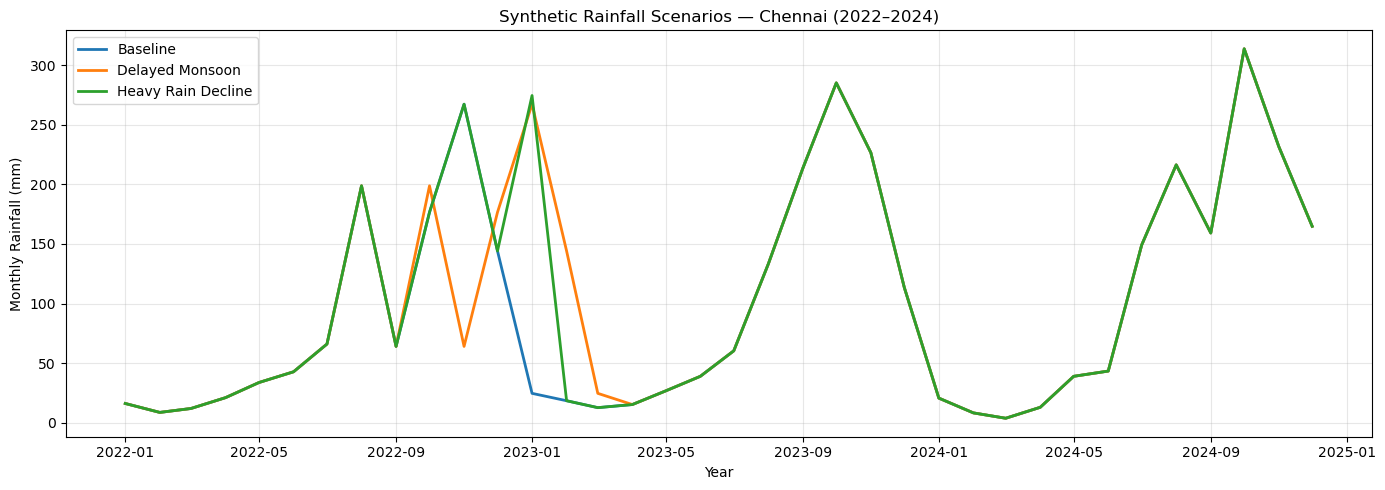

In [2]:

# comparing rainfall across climate scenarios

district = "chn"

selected_scenarios = [
    "baseline",
    "delayed_monsoon",
    "heavy_rain_decline"
]

# Select Chennai, evaluation period, and chosen scenarios
rainfall_comparison = climate[
    (climate["district_id"] == district) &
    (climate["year_month"] >= "2022-01-01") &
    (climate["scenario_id"].isin(selected_scenarios))
].copy()

plt.figure(figsize=(14, 5))

for scenario in selected_scenarios:
    subset = rainfall_comparison[
        rainfall_comparison["scenario_id"] == scenario
    ].sort_values("year_month")

    plt.plot(
        subset["year_month"],
        subset["rainfall_mm"],
        label=scenario.replace("_", " ").title(),
        linewidth=2
    )

plt.title(
    "Synthetic Rainfall Scenarios — Chennai (2022–2024)"
)
plt.xlabel("Year")
plt.ylabel("Monthly Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [3]:

#  Quantify rainfall anomalies relative to baseline

# Select Chennai during the scenario evaluation period
chennai_rain = climate[
    (climate["district_id"] == "chn") &
    (climate["year_month"] >= "2022-01-01")
].copy()

# Convert scenarios into separate columns
rain_pivot = chennai_rain.pivot(
    index="year_month",
    columns="scenario_id",
    values="rainfall_mm"
)

# Calculate differences from baseline rainfall
rain_anomalies = rain_pivot.subtract(
    rain_pivot["baseline"],
    axis=0
)

# Baseline minus itself is always zero
rain_anomalies = rain_anomalies.drop(
    columns="baseline"
)

print("=== RAINFALL ANOMALY SUMMARY ===")

summary = pd.DataFrame({
    "Months changed": (rain_anomalies.abs() > 1e-6).sum(),
    "Maximum increase (mm)": rain_anomalies.max(),
    "Maximum decrease (mm)": rain_anomalies.min()
})

display(summary.round(2))

print("\n=== MODIFIED MONTHS: DELAYED MONSOON ===")

display(
    rain_anomalies.loc[
        rain_anomalies["delayed_monsoon"].abs() > 1e-6,
        ["delayed_monsoon"]
    ]
)


=== RAINFALL ANOMALY SUMMARY ===


,Months changed,Maximum increase (mm),Maximum decrease (mm)
scenario_id,,,
delayed_monsoon,6,242.7,-203.3
heavy_rain_decline,1,250.0,0.0
irregular_rain,12,220.0,0.0
prolonged_wet,4,137.4,0.0
warm_wet,6,107.0,0.0
warmer,0,0.0,0.0



=== MODIFIED MONTHS: DELAYED MONSOON ===


scenario_id,delayed_monsoon
year_month,
2022-10-01,22.2
2022-11-01,-203.3
2022-12-01,32.5
2023-01-01,242.7
2023-02-01,125.7
2023-03-01,12.0


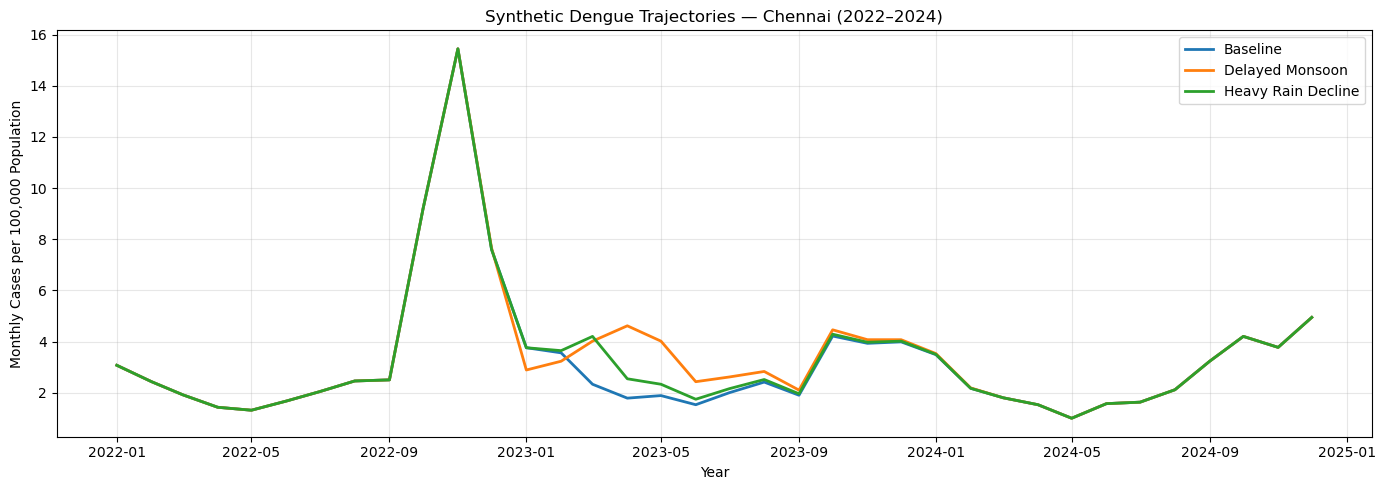

In [4]:

# Compare synthetic dengue trajectories

selected_scenarios = [
    "baseline",
    "delayed_monsoon",
    "heavy_rain_decline"
]

dengue_comparison = cases[
    (cases["district_id"] == "chn") &
    (cases["disease_id"] == "dengue") &
    (cases["year_month"] >= "2022-01-01") &
    (cases["scenario_id"].isin(selected_scenarios))
].copy()

plt.figure(figsize=(14, 5))

for scenario in selected_scenarios:
    subset = dengue_comparison[
        dengue_comparison["scenario_id"] == scenario
    ].sort_values("year_month")

    plt.plot(
        subset["year_month"],
        subset["cases_per_100k"],
        label=scenario.replace("_", " ").title(),
        linewidth=2
    )

plt.title(
    "Synthetic Dengue Trajectories — Chennai (2022–2024)"
)
plt.xlabel("Year")
plt.ylabel("Monthly Cases per 100,000 Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
# What the graph reveals:
#
# | Period                    | Observation                                    |
# |---------------------------|------------------------------------------------|
# | October–November 2022     | All three scenarios share a major dengue peak  |
# |                           | of approximately 15.5 cases per 100,000.       |
# | December 2022–January 2023| Cases decline sharply across the scenarios.    |
# | March–June 2023           | The delayed-monsoon scenario (orange) produces |
# |                           | a noticeable secondary rise compared with the  |
# |                           | baseline (blue).                               |
# | Late 2023–2024            | The trajectories largely converge again.       |

In [6]:

#  Quantify dengue case differences from baseline

chennai_dengue = cases[
    (cases["district_id"] == "chn") &
    (cases["disease_id"] == "dengue") &
    (cases["year_month"] >= "2022-01-01")
].copy()

case_pivot = chennai_dengue.pivot(
    index="year_month",
    columns="scenario_id",
    values="cases_per_100k"
)

case_anomalies = case_pivot.subtract(
    case_pivot["baseline"],
    axis=0
).drop(columns="baseline")

case_summary = pd.DataFrame({
    "Months changed": (case_anomalies.abs() > 1e-6).sum(),
    "Largest increase per 100k": case_anomalies.max(),
    "Largest decrease per 100k": case_anomalies.min(),
    "Cumulative difference per 100k": case_anomalies.sum()
})

print("=== DENGUE SCENARIO IMPACT — CHENNAI ===")
display(case_summary.round(3))

print("\n=== DELAYED MONSOON: MONTHS WITH CASE CHANGES ===")
display(
    case_anomalies.loc[
        case_anomalies["delayed_monsoon"].abs() > 1e-6,
        ["delayed_monsoon"]
    ].round(3)
)


=== DENGUE SCENARIO IMPACT — CHENNAI ===


,Months changed,Largest increase per 100k,Largest decrease per 100k,Cumulative difference per 100k
scenario_id,,,,
delayed_monsoon,15,2.828,-0.871,8.156
heavy_rain_decline,12,1.871,0.000,3.841
irregular_rain,23,3.185,-0.229,29.984
prolonged_wet,14,5.085,0.000,15.156
warm_wet,28,0.871,-1.172,-12.187
warmer,29,0.686,-1.172,-13.542



=== DELAYED MONSOON: MONTHS WITH CASE CHANGES ===


scenario_id,delayed_monsoon
year_month,
2022-12-01,0.057
2023-01-01,-0.871
2023-02-01,-0.328
2023-03-01,1.685
2023-04-01,2.828
2023-05-01,2.128
2023-06-01,0.900
2023-07-01,0.614
2023-08-01,0.415


In [7]:
# The pattern is interesting: cases initially decrease relative to baseline,
# then increase during March–May 2023.
#
# This gives us a candidate secondary outbreak wave to investigate in our
# recovery engine. It does not yet prove that sustained recovery was
# interrupted.

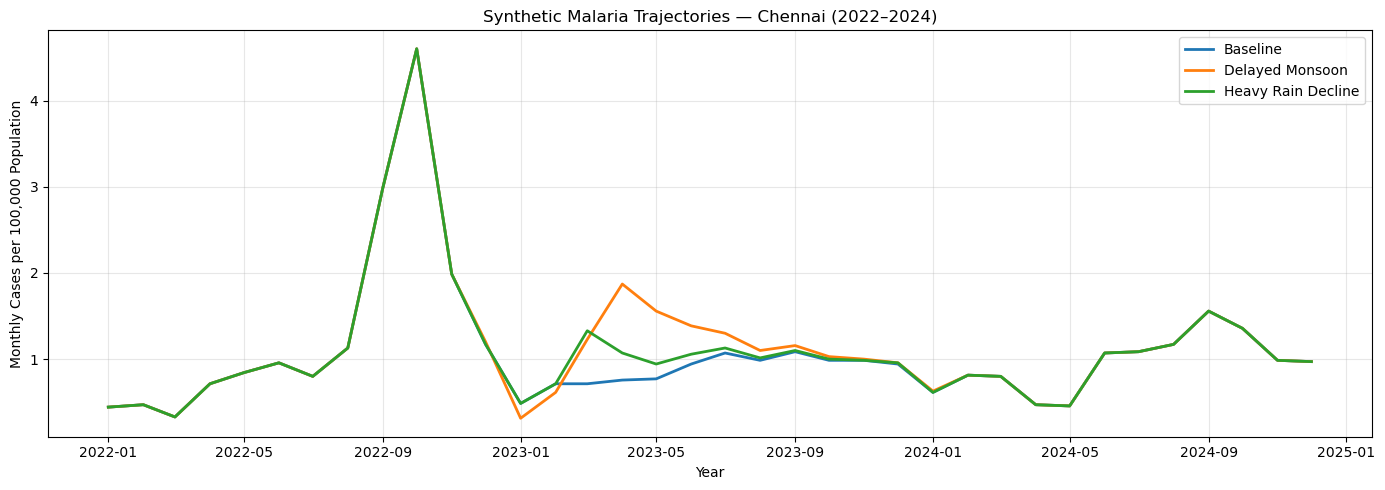

In [8]:

# Compare malaria trajectories across climate scenarios

selected_scenarios = [
    "baseline",
    "delayed_monsoon",
    "heavy_rain_decline"
]

malaria_comparison = cases[
    (cases["district_id"] == "chn") &
    (cases["disease_id"] == "malaria") &
    (cases["year_month"] >= "2022-01-01") &
    (cases["scenario_id"].isin(selected_scenarios))
].copy()

plt.figure(figsize=(14, 5))

for scenario in selected_scenarios:
    subset = malaria_comparison[
        malaria_comparison["scenario_id"] == scenario
    ].sort_values("year_month")

    plt.plot(
        subset["year_month"],
        subset["cases_per_100k"],
        label=scenario.replace("_", " ").title(),
        linewidth=2
    )

plt.title("Synthetic Malaria Trajectories — Chennai (2022–2024)")
plt.xlabel("Year")
plt.ylabel("Monthly Cases per 100,000 Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

#  Rainfall lag correlations by disease
# Baseline scenario, training period only

lag_data = cases[
    (cases["scenario_id"] == "baseline") &
    (cases["year_month"] < "2022-01-01")
].merge(
    climate[
        (climate["scenario_id"] == "baseline") &
        (climate["year_month"] < "2022-01-01")
    ][["year_month", "district_id", "rainfall_mm"]],
    on=["year_month", "district_id"],
    how="left",
    validate="many_to_one"
).sort_values(
    ["disease_id", "district_id", "year_month"]
)

# Create rainfall lags within each district and disease
for lag in range(4):
    lag_data[f"rainfall_lag_{lag}"] = (
        lag_data.groupby(
            ["disease_id", "district_id"]
        )["rainfall_mm"].shift(lag)
    )

results = []

for disease in ["dengue", "malaria"]:
    subset = lag_data[
        lag_data["disease_id"] == disease
    ]

    for lag in range(4):
        correlation = subset[
            ["cases_per_100k", f"rainfall_lag_{lag}"]
        ].corr().iloc[0, 1]

        results.append({
            "Disease": disease,
            "Lag (months)": lag,
            "Correlation": correlation
        })

lag_results = pd.DataFrame(results)

display(
    lag_results.pivot(
        index="Lag (months)",
        columns="Disease",
        values="Correlation"
    ).round(3)
)


Disease,dengue,malaria
Lag (months),,
0,0.333,0.344
1,0.442,0.184
2,0.416,0.053
3,0.271,-0.125


In [10]:

#  Climate lag correlations for both diseases

climate_features = [
    "rainfall_mm",
    "mean_temperature_c",
    "relative_humidity_pct"
]

# Rebuild baseline training data with all climate variables
lag_data_full = cases[
    (cases["scenario_id"] == "baseline") &
    (cases["year_month"] < "2022-01-01")
].merge(
    climate[
        (climate["scenario_id"] == "baseline") &
        (climate["year_month"] < "2022-01-01")
    ][["year_month", "district_id"] + climate_features],
    on=["year_month", "district_id"],
    how="left",
    validate="many_to_one"
).sort_values(
    ["disease_id", "district_id", "year_month"]
)

results = []

for variable in climate_features:
    for lag in range(4):

        lag_column = f"{variable}_lag_{lag}"

        lag_data_full[lag_column] = (
            lag_data_full.groupby(
                ["disease_id", "district_id"]
            )[variable].shift(lag)
        )

        for disease in ["dengue", "malaria"]:
            subset = lag_data_full[
                lag_data_full["disease_id"] == disease
            ]

            correlation = subset[
                ["cases_per_100k", lag_column]
            ].corr().iloc[0, 1]

            results.append({
                "Disease": disease,
                "Climate Variable": variable,
                "Lag (months)": lag,
                "Correlation": correlation
            })

climate_lag_results = pd.DataFrame(results)

display(
    climate_lag_results.pivot_table(
        index=["Climate Variable", "Lag (months)"],
        columns="Disease",
        values="Correlation"
    ).round(3)
)


Disease                             dengue  malaria
Climate Variable      Lag (months)                 
mean_temperature_c    0             -0.584   -0.155
                      1             -0.531    0.087
                      2             -0.326    0.312
                      3             -0.059    0.489
rainfall_mm           0              0.333    0.344
                      1              0.442    0.184
                      2              0.416    0.053
                      3              0.271   -0.125
relative_humidity_pct 0              0.336    0.303
                      1              0.426    0.156
                      2              0.424    0.005
                      3              0.292   -0.119

In [11]:

# Verify climate changes across all scenarios
# Chennai, 2022–2024

variables = [
    "rainfall_mm",
    "mean_temperature_c",
    "relative_humidity_pct"
]

subset = climate[
    (climate["district_id"] == "chn") &
    (climate["year_month"] >= "2022-01-01")
].copy()

summary_rows = []

for variable in variables:
    pivot = subset.pivot(
        index="year_month",
        columns="scenario_id",
        values=variable
    )

    anomalies = pivot.subtract(
        pivot["baseline"],
        axis=0
    ).drop(columns="baseline")

    for scenario in anomalies.columns:
        differences = anomalies[scenario]

        summary_rows.append({
            "Scenario": scenario,
            "Variable": variable,
            "Months changed": (differences.abs() > 1e-6).sum(),
            "Maximum increase": differences.max(),
            "Maximum decrease": differences.min()
        })

climate_scenario_summary = pd.DataFrame(summary_rows)

display(
    climate_scenario_summary.sort_values(
        ["Scenario", "Variable"]
    ).round(2)
)


,Scenario,Variable,Months changed,Maximum increase,Maximum decrease
6,delayed_monsoon,mean_temperature_c,0,0.0,0.0
0,delayed_monsoon,rainfall_mm,6,242.7,-203.3
12,delayed_monsoon,relative_humidity_pct,6,4.9,-4.0
7,heavy_rain_decline,mean_temperature_c,0,0.0,0.0
1,heavy_rain_decline,rainfall_mm,1,250.0,0.0
13,heavy_rain_decline,relative_humidity_pct,1,5.0,0.0
8,irregular_rain,mean_temperature_c,0,0.0,0.0
2,irregular_rain,rainfall_mm,12,220.0,0.0
14,irregular_rain,relative_humidity_pct,12,4.4,0.0
9,prolonged_wet,mean_temperature_c,0,0.0,0.0
